# Exposure forecasting

We forecast next-day SO2 emission and plume drift, compute a Gaussian plume index per barangay-day, and train
an exposure model on the team-verified report log. Outputs:

1. `data/processed/next_day_forecasts.csv`: next-day SO2 (t/d) and drift sector for every date
2. `data/processed/exposure_scores.csv`: plume index, exposure probability and flag per barangay-day (221,400 rows)
3. `data/processed/exposure_shap_top3.csv`: top 3 SHAP features per barangay-day in 2026
4. `models/`, `results/metrics.json`, `results/tables/model_comparison.csv`, `results/figures/`

Every model, scaler, grid search and threshold is fit on 2024-2025 only. 2026 is used once, for evaluation.

## Setup

In [1]:
import json
import sys
from pathlib import Path

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.compose import TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut, TimeSeriesSplit, cross_val_predict
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

ROOT = Path.cwd() if (Path.cwd() / "requirements.txt").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import evaluation, geo, plume

RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
MODELS = ROOT / "models"
RESULTS = ROOT / "results"
FIGURES = RESULTS / "figures"
TABLES = RESULTS / "tables"
for folder in (MODELS, FIGURES, TABLES):
    folder.mkdir(parents=True, exist_ok=True)

TRAIN_END = pd.Timestamp("2025-12-31")
RANDOM_STATE = 42
TARGET_DRIFT_ACCURACY = 0.60
TARGET_RECALL = 0.75

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)


def show(df, name):
    """Print row count and missing values per column."""
    print(f"{name}: {len(df):,} rows x {df.shape[1]} columns")
    na = df.isna().sum()
    na = na[na > 0]
    print("  missing:", "none" if na.empty else na.to_dict())


metrics = {}
comparison = []

.\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load data

In [2]:
volcano = pd.read_csv(PROCESSED / "volcano_daily.csv", parse_dates=["date"]).set_index("date")
print(f"volcano_daily: {len(volcano):,} rows x {volcano.shape[1]} columns, "
      f"{volcano.isna().any().sum()} columns with missing values")
print(volcano["split"].value_counts().to_string())
assert volcano.index[volcano["split"] == "train"].max() == TRAIN_END

PANEL_COLUMNS = ["adm4_psgc", "date", "split", "exposed", "report_day", "angle_diff_deg", "dist_km", "bearing_deg",
                 "elev_m", "wind_speed_plume", "eq_total_lag1", "eq_total_lag2", "eq_total_lag3", "eq_total_roll7"]
panel = pd.read_csv(PROCESSED / "barangay_daily_panel.csv", usecols=PANEL_COLUMNS, parse_dates=["date"])
show(panel, "barangay_daily_panel")
assert len(panel) == 221_400

volcano_daily: 1,025 rows x 81 columns, 69 columns with missing values
split
train    731
test     294


barangay_daily_panel: 221,400 rows x 14 columns
  missing: {'angle_diff_deg': 216, 'wind_speed_plume': 216, 'eq_total_lag1': 1944, 'eq_total_lag2': 2160, 'eq_total_lag3': 2376}


## Next-day SO2 emission

The target is log1p of the daily mean SO2 emission (t/d) on day t+1, predicted from values known on day t.
A row is used for fitting only when day t+1 has a reading and falls in 2024-2025.

In [3]:
daily = volcano.copy()
daily["target_date"] = daily.index + pd.Timedelta(days=1)
daily["so2_next_td"] = daily["so2_mean"].shift(-1)
daily["log_so2_today"] = np.log1p(daily["so2_mean"])
daily["log_so2_last"] = np.log1p(daily["so2_last"])
daily["log_so2_roll7"] = np.log1p(daily["so2_mean_roll7"])
for k in range(1, 8):
    daily[f"log_so2_lag{k}"] = np.log1p(daily[f"so2_mean_lag{k}"])
# earthquake counts are heavy-tailed and reach values in 2026 never seen in training, so they enter on a log scale
EQ_COUNTS = ["eq_total", "eq_vt", "eq_lfvq", "eq_total_lag1", "eq_total_lag2", "eq_total_roll7"]
for col in EQ_COUNTS:
    daily[f"log_{col}"] = np.log1p(daily[col])

SO2_FEATURES = (["log_so2_today", "log_so2_last", "so2_days_since", "log_so2_roll7"]
                + [f"log_so2_lag{k}" for k in range(1, 8)]
                + [f"log_{col}" for col in EQ_COUNTS]
                + ["plume_height_max", "plume_height_max_roll7", "plume_intensity_max", "ash_plume_obs",
                   "wind_speed_plume", "wind_speed_10m"])

has_target = daily["so2_next_td"].notna()
so2_train = daily[has_target & (daily["target_date"] <= TRAIN_END)]
so2_test = daily[has_target & (daily["target_date"] > TRAIN_END)]
show(so2_train[SO2_FEATURES], "SO2 training rows (features)")
show(so2_test[SO2_FEATURES], "SO2 test rows (features)")
X_so2_train, y_so2_train = so2_train[SO2_FEATURES], np.log1p(so2_train["so2_next_td"])

SO2 training rows (features): 564 rows x 23 columns
  missing: {'log_so2_today': 76, 'log_so2_lag1': 70, 'log_so2_lag2': 70, 'log_so2_lag3': 78, 'log_so2_lag4': 77, 'log_so2_lag5': 81, 'log_so2_lag6': 77, 'log_so2_lag7': 84, 'log_eq_total': 3, 'log_eq_vt': 3, 'log_eq_lfvq': 3, 'log_eq_total_lag1': 3, 'log_eq_total_lag2': 3, 'plume_height_max': 77, 'plume_height_max_roll7': 9, 'plume_intensity_max': 79}
SO2 test rows (features): 290 rows x 23 columns
  missing: {'log_so2_today': 5, 'log_so2_lag1': 5, 'log_so2_lag2': 5, 'log_so2_lag3': 5, 'log_so2_lag4': 5, 'log_so2_lag5': 5, 'log_so2_lag6': 5, 'log_so2_lag7': 5, 'log_eq_total': 1, 'log_eq_vt': 1, 'log_eq_lfvq': 1, 'log_eq_total_lag1': 1, 'log_eq_total_lag2': 1, 'plume_height_max': 28, 'plume_height_max_roll7': 1, 'plume_intensity_max': 28}


Both models are tuned with a small grid and 5-fold `TimeSeriesSplit` on the training rows, scored by MAE on the
log scale. The MLP gets median imputation and standard scaling of inputs and target, all fit inside each fold.

In [4]:
so2_cv = TimeSeriesSplit(n_splits=5)
so2_lgbm_search = GridSearchCV(
    lgb.LGBMRegressor(random_state=RANDOM_STATE, verbose=-1),
    {"num_leaves": [7, 15], "learning_rate": [0.03, 0.1], "n_estimators": [200, 500],
     "min_child_samples": [10, 30]},
    cv=so2_cv, scoring="neg_mean_absolute_error",
).fit(X_so2_train, y_so2_train)

so2_mlp_search = GridSearchCV(
    TransformedTargetRegressor(
        regressor=make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                                MLPRegressor(max_iter=3000, random_state=RANDOM_STATE)),
        transformer=StandardScaler()),
    {"regressor__mlpregressor__hidden_layer_sizes": [(16,), (32, 16)],
     "regressor__mlpregressor__alpha": [1.0, 10.0, 30.0]},
    cv=so2_cv, scoring="neg_mean_absolute_error",
).fit(X_so2_train, y_so2_train)

for name, search in [("LightGBM", so2_lgbm_search), ("MLP", so2_mlp_search)]:
    print(f"{name}: CV MAE (log scale) {-search.best_score_:.3f} | {search.best_params_}")

LightGBM: CV MAE (log scale) 0.409 | {'learning_rate': 0.03, 'min_child_samples': 30, 'n_estimators': 200, 'num_leaves': 15}
MLP: CV MAE (log scale) 0.406 | {'regressor__mlpregressor__alpha': 10.0, 'regressor__mlpregressor__hidden_layer_sizes': (16,)}


Baselines: persistence repeats the last observed daily mean, and the 7-day mean averages the readings of the past
seven days (or repeats the last observed value when there are none). Errors are in t/d on 2026 target days.

In [5]:
# predictions are kept within the range of training targets so the MLP cannot extrapolate to extreme values
log_so2_range = (y_so2_train.min(), y_so2_train.max())
so2_predictions = pd.DataFrame({
    "LightGBM": np.expm1(np.clip(so2_lgbm_search.predict(daily[SO2_FEATURES]), *log_so2_range)),
    "MLP": np.expm1(np.clip(so2_mlp_search.predict(daily[SO2_FEATURES]), *log_so2_range)),
    "persistence": daily["so2_last"].to_numpy(),
    "7-day mean": daily["so2_mean_roll7"].fillna(daily["so2_last"]).to_numpy(),
}, index=daily.index)

so2_rows = []
for name in so2_predictions:
    pred = so2_predictions.loc[so2_test.index, name]
    so2_rows.append({
        "model": name,
        "kind": "model" if name in ("LightGBM", "MLP") else "baseline",
        "mae_td": mean_absolute_error(so2_test["so2_next_td"], pred),
        "rmse_td": np.sqrt(mean_squared_error(so2_test["so2_next_td"], pred)),
        "n_eval": len(pred),
    })
so2_results = pd.DataFrame(so2_rows).set_index("model")
print(f"Next-day SO2, 2026 target days with a reading ({len(so2_test)} days)")
so2_results.round(1)

Next-day SO2, 2026 target days with a reading (290 days)


,kind,mae_td,rmse_td,n_eval
model,,,,
LightGBM,model,687.9,875.2,290
MLP,model,633.4,807.8,290
persistence,baseline,784.3,1021.3,290
7-day mean,baseline,657.8,821.3,290


The final SO2 model is the one with the lower 2024-2025 cross-validated MAE, so the choice does not look at 2026.
Its forecast feeds the plume index on 2026 days; the other model is reported as a comparison.

In [6]:
so2_cv_mae = {"LightGBM": -so2_lgbm_search.best_score_, "MLP": -so2_mlp_search.best_score_}
SO2_FORECAST_MODEL = min(so2_cv_mae, key=so2_cv_mae.get)
daily["so2_forecast_next_td"] = so2_predictions[SO2_FORECAST_MODEL]
print("SO2 forecast model (lowest CV MAE):", SO2_FORECAST_MODEL)

SO2 forecast model (lowest CV MAE): MLP


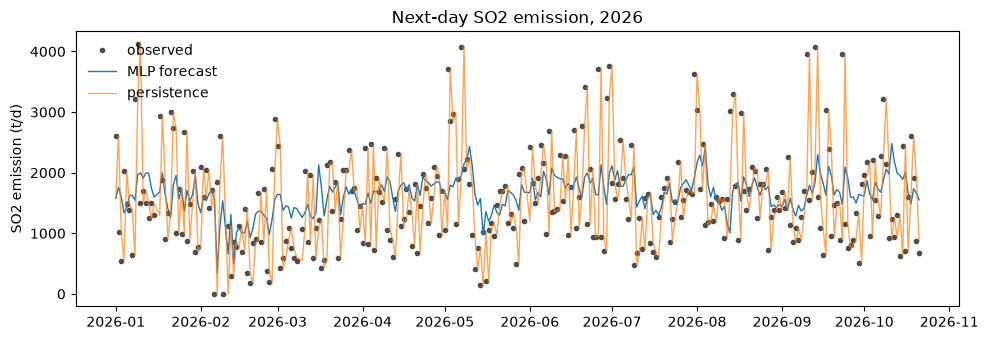

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.5))
target_dates = so2_test["target_date"]
ax.plot(target_dates, so2_test["so2_next_td"], ".", color="0.3", label="observed")
ax.plot(target_dates, so2_predictions.loc[so2_test.index, SO2_FORECAST_MODEL], lw=1,
        label=f"{SO2_FORECAST_MODEL} forecast")
ax.plot(target_dates, so2_predictions.loc[so2_test.index, "persistence"], lw=1, alpha=0.7, label="persistence")
ax.set_ylabel("SO2 emission (t/d)")
ax.set_title("Next-day SO2 emission, 2026")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "so2_next_day_2026.png", dpi=150)

joblib.dump(so2_lgbm_search.best_estimator_, MODELS / "so2_next_day_lgbm.joblib")
joblib.dump(so2_mlp_search.best_estimator_, MODELS / "so2_next_day_mlp.joblib")
metrics["so2_next_day"] = {
    "n_train": len(so2_train), "n_test": len(so2_test),
    "lgbm_params": so2_lgbm_search.best_params_,
    "mlp_params": {k: str(v) for k, v in so2_mlp_search.best_params_.items()},
    "cv_mae_log": {k: round(v, 4) for k, v in so2_cv_mae.items()},
    "forecast_model": SO2_FORECAST_MODEL,
    "test": so2_results.drop(columns="kind").round(2).to_dict(orient="index"),
}
comparison += [{"task": "next-day SO2", "model": name, **row} for name, row in so2_results.to_dict("index").items()]

## Next-day plume drift

The target is the observed drift sector (8 sectors) on day t+1. Day t+1's plume height is not known a day ahead, so
its wind (same hourly file, 06:00 to 18:00) is interpolated at day t's plume altitude. The Open-Meteo history stands
in for a wind forecast, so the skill shown is an upper bound for operational use.

In [8]:
wind_raw = pd.read_csv(RAW / "wind_kanlaon_hourly.csv")
show(wind_raw, "wind_raw")
wind_raw["time"] = pd.to_datetime(wind_raw["time"])
wind_raw["date"] = wind_raw["time"].dt.normalize()
wind_day = wind_raw[wind_raw["time"].dt.hour.between(6, 18)]
show(wind_day, "wind_day (06:00-18:00)")
print("wind dates:", wind_day["date"].min().date(), "to", wind_day["date"].max().date())

train_plume_height = volcano.loc[:TRAIN_END, "plume_height_median"].median()
plume_alt = geo.CRATER_ELEV_M + volcano["plume_height_median"].fillna(train_plume_height)

same_day_wind = geo.daily_plume_wind(wind_day, plume_alt).reindex(volcano.index)
check = geo.angle_diff_deg(same_day_wind["wind_drift_deg"], volcano["wind_drift_deg"])
print(f"check against volcano_daily (same-day altitude): max drift difference {np.nanmax(check):.6f} deg")

next_day_wind = geo.daily_plume_wind(wind_day, plume_alt.shift(1, freq="D"))
show(next_day_wind, "next_day_wind (wind on day t+1 at day t plume altitude)")

wind_raw: 24,576 rows x 9 columns
  missing: none
wind_day (06:00-18:00): 13,312 rows x 10 columns
  missing: none
wind dates: 2024-01-01 to 2026-10-20
check against volcano_daily (same-day altitude): max drift difference 0.000000 deg
next_day_wind (wind on day t+1 at day t plume altitude): 1,024 rows x 3 columns
  missing: {'wind_speed_plume': 1, 'wind_dir_plume': 1, 'wind_drift_deg': 1}


In [9]:
next_wind = next_day_wind.reindex(daily["target_date"])
daily["next_wind_drift_sin"] = np.sin(np.radians(next_wind["wind_drift_deg"])).to_numpy()
daily["next_wind_drift_cos"] = np.cos(np.radians(next_wind["wind_drift_deg"])).to_numpy()
daily["next_wind_speed"] = next_wind["wind_speed_plume"].to_numpy()
daily["next_wind_sector"] = geo.deg_to_sector(next_wind["wind_drift_deg"].to_numpy())

# today's drift sector; on days without an observation, the last observed sector is carried forward
daily["drift_last_sector"] = daily["drift_obs_sector"].ffill()
drift_last_rad = np.radians(daily["drift_last_sector"].map(geo.SECTOR_DEG))
daily["drift_last_sin"] = np.sin(drift_last_rad)
daily["drift_last_cos"] = np.cos(drift_last_rad)
daily["drift_observed_today"] = daily["drift_obs_sector"].notna().astype(int)
daily["drift_next_sector"] = daily["drift_obs_sector"].shift(-1)

DRIFT_FEATURES = ["next_wind_drift_sin", "next_wind_drift_cos", "next_wind_speed",
                  "drift_last_sin", "drift_last_cos", "drift_observed_today", "plume_height_median"]

has_drift = daily["drift_next_sector"].notna()
drift_train = daily[has_drift & (daily["target_date"] <= TRAIN_END)]
drift_test = daily[has_drift & (daily["target_date"] > TRAIN_END)]
show(drift_train[DRIFT_FEATURES], "drift training rows (features)")
show(drift_test[DRIFT_FEATURES], "drift test rows (features)")
print("training sectors:", drift_train["drift_next_sector"].value_counts().to_dict())

drift training rows (features): 608 rows x 7 columns
  missing: {'plume_height_median': 51}
drift test rows (features): 265 rows x 7 columns
  missing: {'next_wind_drift_sin': 1, 'next_wind_drift_cos': 1, 'next_wind_speed': 1, 'plume_height_median': 12}
training sectors: {'SW': 203, 'W': 127, 'NW': 86, 'NE': 68, 'S': 47, 'SE': 37, 'E': 24, 'N': 16}


Both classifiers are tuned with a small grid and 5-fold `TimeSeriesSplit` on 2024-2025, scored by accuracy.
The one with the higher cross-validated accuracy is the final drift model; the other is reported as a comparison.

In [10]:
X_drift_train, y_drift_train = drift_train[DRIFT_FEATURES], drift_train["drift_next_sector"]
drift_cv = TimeSeriesSplit(n_splits=5)
drift_lgbm_search = GridSearchCV(
    lgb.LGBMClassifier(random_state=RANDOM_STATE, verbose=-1),
    {"num_leaves": [4, 8], "learning_rate": [0.03, 0.1], "n_estimators": [100, 300],
     "min_child_samples": [10, 30]},
    cv=drift_cv, scoring="accuracy",
).fit(X_drift_train, y_drift_train)

drift_mlp_search = GridSearchCV(
    make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                  MLPClassifier(max_iter=3000, random_state=RANDOM_STATE)),
    {"mlpclassifier__hidden_layer_sizes": [(16,), (32, 16)], "mlpclassifier__alpha": [0.1, 1.0, 10.0]},
    cv=drift_cv, scoring="accuracy",
).fit(X_drift_train, y_drift_train)

for name, search in [("LightGBM", drift_lgbm_search), ("MLP", drift_mlp_search)]:
    print(f"{name}: CV accuracy {search.best_score_:.3f} | {search.best_params_}")

LightGBM: CV accuracy 0.446 | {'learning_rate': 0.03, 'min_child_samples': 10, 'n_estimators': 100, 'num_leaves': 4}
MLP: CV accuracy 0.485 | {'mlpclassifier__alpha': 1.0, 'mlpclassifier__hidden_layer_sizes': (16,)}


We score one prediction per 2026 day with an observed drift, against two baselines (repeat the most recent observed
sector, and always SW) and, for reference, the plume-level wind sector for t+1. Exact accuracy is the target
measure; within one sector (45 degrees) is a more lenient secondary measure.

In [11]:
drift_predictions = pd.DataFrame({
    "LightGBM": drift_lgbm_search.predict(daily[DRIFT_FEATURES]),
    "MLP": drift_mlp_search.predict(daily[DRIFT_FEATURES]),
    "repeat yesterday": daily["drift_last_sector"].to_numpy(),
    "always SW": "SW",
    "wind sector (reference)": daily["next_wind_sector"].to_numpy(),
}, index=daily.index)

DRIFT_KIND = {"LightGBM": "model", "MLP": "model", "repeat yesterday": "baseline", "always SW": "baseline",
              "wind sector (reference)": "reference"}
drift_rows = []
for name in drift_predictions:
    pred = drift_predictions.loc[drift_test.index, name]
    gap = evaluation.sector_gap(pred, drift_test["drift_next_sector"])
    drift_rows.append({"model": name, "kind": DRIFT_KIND[name], "accuracy": np.mean(gap == 0),
                       "within_one_accuracy": np.mean(gap <= 1), "n_eval": len(pred)})
drift_results = pd.DataFrame(drift_rows).set_index("model")
print(f"Next-day drift, 2026 days with observed drift ({len(drift_test)} days); target accuracy >= {TARGET_DRIFT_ACCURACY:.0%}")
drift_results.round(3)

Next-day drift, 2026 days with observed drift (265 days); target accuracy >= 60%


,kind,accuracy,within_one_accuracy,n_eval
model,,,,
LightGBM,model,0.558,0.887,265
MLP,model,0.509,0.875,265
repeat yesterday,baseline,0.430,0.770,265
always SW,baseline,0.355,0.596,265
wind sector (reference),reference,0.483,0.932,265


In [12]:
print("LightGBM confusion matrix on 2026 (rows observed, columns predicted)")
pd.crosstab(drift_test["drift_next_sector"], drift_predictions.loc[drift_test.index, "LightGBM"],
            rownames=["observed"], colnames=["predicted"])

LightGBM confusion matrix on 2026 (rows observed, columns predicted)


predicted,E,NE,NW,S,SE,SW,W
observed,,,,,,,
E,12,12,0,1,2,0,0
N,0,3,1,0,0,1,0
NE,3,11,2,1,3,0,0
NW,0,2,8,0,0,4,2
S,0,0,0,6,12,12,0
SE,4,1,1,2,24,7,0
SW,0,0,1,2,5,79,7
W,0,0,2,0,1,23,8


In [13]:
drift_cv_acc = {"LightGBM": drift_lgbm_search.best_score_, "MLP": drift_mlp_search.best_score_}
DRIFT_FORECAST_MODEL = max(drift_cv_acc, key=drift_cv_acc.get)
drift_search = drift_lgbm_search if DRIFT_FORECAST_MODEL == "LightGBM" else drift_mlp_search
daily["drift_forecast_next_sector"] = drift_predictions[DRIFT_FORECAST_MODEL]
daily["drift_forecast_next_prob"] = drift_search.predict_proba(daily[DRIFT_FEATURES]).max(axis=1)
print("drift forecast model (highest CV accuracy):", DRIFT_FORECAST_MODEL)

joblib.dump(drift_lgbm_search.best_estimator_, MODELS / "drift_next_day_lgbm.joblib")
joblib.dump(drift_mlp_search.best_estimator_, MODELS / "drift_next_day_mlp.joblib")
metrics["drift_next_day"] = {
    "n_train": len(drift_train), "n_test": len(drift_test),
    "lgbm_params": drift_lgbm_search.best_params_,
    "mlp_params": {k: str(v) for k, v in drift_mlp_search.best_params_.items()},
    "cv_accuracy": {k: round(v, 4) for k, v in drift_cv_acc.items()},
    "forecast_model": DRIFT_FORECAST_MODEL,
    "test": drift_results.drop(columns="kind").round(4).to_dict(orient="index"),
}
comparison += [{"task": "next-day drift", "model": name, **row} for name, row in drift_results.to_dict("index").items()]

drift forecast model (highest CV accuracy): MLP


## Gaussian plume index

Each barangay-day gets a steady-state Gaussian plume value from `src/plume.py` (Briggs rural class D sigmas, ground
reflection, wind speed at least 1 m/s, zero upwind). Q is the observed SO2 on 2024-2025 days (last observed value on
days without a reading) and the next-day forecast on 2026 days.

The two versions differ only in the effective height H:
- `plume_index_flat` (the specified formula): H = max(2,435 m + plume height - barangay elevation, 10 m). With H
  between about 1,650 and 2,650 m and sigma_z at most about 265 m within 30 km, the vertical term is close to zero
  at every barangay.
- `plume_index` (terrain-following): H = max(plume height above the crater, 10 m), as if the plume followed the
  slope down. The exposure model uses this version, and it is saved to `exposure_scores.csv`.

Both are relative indices, not calibrated concentrations, so we do not compare them with the WHO guideline; the
health impact in notebook 03 uses SO2 scenarios instead.

In [14]:
daily["so2_forecast_td"] = daily["so2_forecast_next_td"].shift(1)
daily["so2_input_td"] = np.where(daily["split"] == "train", daily["so2_last"], daily["so2_forecast_td"])
daily["plume_height_m"] = daily["plume_height_median"].fillna(train_plume_height)
print(f"2024-2025 median plume height used on days without a height: {train_plume_height:.0f} m")
show(daily[["so2_input_td", "plume_height_m"]], "daily plume inputs")

panel = panel.merge(daily[["so2_input_td", "plume_height_m"]].reset_index(), on="date", how="left", validate="m:1")
show(panel, "panel + plume inputs")

plume_args = dict(q_td=panel["so2_input_td"], wind_speed_ms=panel["wind_speed_plume"],
                  plume_height_m=panel["plume_height_m"], elev_m=panel["elev_m"], dist_km=panel["dist_km"],
                  angle_diff_deg=panel["angle_diff_deg"])
panel["plume_index_flat"] = plume.compute_plume_index(**plume_args, terrain="flat")
panel["plume_index"] = plume.compute_plume_index(**plume_args, terrain="following")
panel.loc[panel["angle_diff_deg"].isna(), ["plume_index_flat", "plume_index"]] = np.nan
show(panel[["plume_index_flat", "plume_index"]], "plume indices")
print("dates without wind (index left empty):",
      sorted(panel.loc[panel["plume_index"].isna(), "date"].dt.date.astype(str).unique()))

2024-2025 median plume height used on days without a height: 200 m
daily plume inputs: 1,025 rows x 2 columns
  missing: none
panel + plume inputs: 221,400 rows x 16 columns
  missing: {'angle_diff_deg': 216, 'wind_speed_plume': 216, 'eq_total_lag1': 1944, 'eq_total_lag2': 2160, 'eq_total_lag3': 2376}
plume indices: 221,400 rows x 2 columns
  missing: {'plume_index_flat': 216, 'plume_index': 216}
dates without wind (index left empty): ['2026-10-21']


In [15]:
downwind = panel["angle_diff_deg"] < 90
print(f"downwind barangay-days (x > 0): {downwind.mean():.1%}")
QUANTILES = [0.5, 0.75, 0.9, 0.99, 1.0]
plume_summary = pd.DataFrame({
    f"{col} ({subset})": panel.loc[mask, col].quantile(QUANTILES)
    for col in ["plume_index_flat", "plume_index"]
    for subset, mask in [("all", panel["plume_index"].notna()), ("downwind", downwind)]
}).T
plume_summary.columns = [f"p{int(q * 100)}" for q in QUANTILES[:-1]] + ["max"]
print("Plume index percentiles (relative units)")
plume_summary.map(lambda v: f"{v:.3g}")

downwind barangay-days (x > 0): 56.7%
Plume index percentiles (relative units)


,p50,p75,p90,p99,max
plume_index_flat (all),0,6.92e-93,3.06e-36,2.82e-19,1.89e-06
plume_index_flat (downwind),8.13e-118,1.8e-46,6.81e-28,3.39e-18,1.89e-06
plume_index (all),0,1.46e-51,0.000435,3.04e+03,1.2e+05
plume_index (downwind),2.13e-73,1.47e-11,16.6,4.55e+03,1.2e+05


In [16]:
plume_by_split = panel.groupby("split")[["plume_index", "plume_index_flat"]].agg(["median", "max"])
print("Plume index by split (relative units)")
plume_by_split.map(lambda v: f"{v:.3g}")

Plume index by split (relative units)


plume_index          plume_index_flat          
           median      max           median       max
split                                                
test            0  4.1e+04                0  2.55e-07
train           0  1.2e+05                0  1.89e-06

In [17]:
metrics["plume_index"] = {
    "downwind_share": round(float(downwind.mean()), 4),
    "plume_index_percentiles": plume_summary.loc["plume_index (all)"].astype(float).to_dict(),
    "plume_index_flat_percentiles": plume_summary.loc["plume_index_flat (all)"].astype(float).to_dict(),
    "train_median_plume_height_m": float(train_plume_height),
}

## Exposure model

We train on report days only (the event dates in the report log), where barangays without a report are known
negatives; other days have no labels. The model scores every barangay-day later.

In [18]:
bearing_rad = np.radians(panel["bearing_deg"])
panel["bearing_sin"] = np.sin(bearing_rad)
panel["bearing_cos"] = np.cos(bearing_rad)
panel["log_plume_index"] = np.log1p(panel["plume_index"])
panel["log_so2_input"] = np.log1p(panel["so2_input_td"])

EXPOSURE_FEATURES = ["dist_km", "bearing_sin", "bearing_cos", "angle_diff_deg", "elev_m", "log_plume_index",
                     "log_so2_input", "plume_height_m", "wind_speed_plume",
                     "eq_total_lag1", "eq_total_lag2", "eq_total_lag3", "eq_total_roll7"]

report_rows = panel[panel["report_day"] == 1]
exp_train = report_rows[report_rows["split"] == "train"].reset_index(drop=True)
exp_test = report_rows[report_rows["split"] == "test"].reset_index(drop=True)
show(exp_train[EXPOSURE_FEATURES + ["exposed"]], "exposure training rows")
show(exp_test[EXPOSURE_FEATURES + ["exposed"]], "exposure test rows")
for name, d in [("train", exp_train), ("test", exp_test)]:
    print(f"{name}: {d['date'].nunique()} event dates, {d['exposed'].sum()} exposed of {len(d):,} rows")

exposure training rows: 1,944 rows x 14 columns
  missing: none
exposure test rows: 1,080 rows x 14 columns
  missing: none
train: 9 event dates, 74 exposed of 1,944 rows
test: 5 event dates, 92 exposed of 1,080 rows


Cross-validation leaves out one event date at a time, so a fold never sees other barangays from its own date, and
scores the grid by PR-AUC. The model with the higher cross-validated PR-AUC is the final exposure model and the
other is reported as a comparison. Each model's threshold is the highest out-of-fold probability that still flags
at least 75% of the exposed 2024-2025 barangay-days.

In [19]:
X_exp_train, y_exp_train, groups_train = exp_train[EXPOSURE_FEATURES], exp_train["exposed"], exp_train["date"]
logo = LeaveOneGroupOut()
scale_pos_weight = (y_exp_train == 0).sum() / (y_exp_train == 1).sum()
print(f"scale_pos_weight: {scale_pos_weight:.1f}")

exp_lgbm_search = GridSearchCV(
    lgb.LGBMClassifier(scale_pos_weight=scale_pos_weight, random_state=RANDOM_STATE, verbose=-1),
    {"num_leaves": [4, 8], "learning_rate": [0.03, 0.1], "n_estimators": [100, 300],
     "min_child_samples": [10, 30]},
    cv=logo, scoring="average_precision",
).fit(X_exp_train, y_exp_train, groups=groups_train)

mlp_weights = compute_sample_weight("balanced", y_exp_train)
exp_mlp_search = GridSearchCV(
    make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                  MLPClassifier(max_iter=3000, random_state=RANDOM_STATE)),
    {"mlpclassifier__hidden_layer_sizes": [(16,), (32, 16)], "mlpclassifier__alpha": [0.1, 1.0, 10.0]},
    cv=logo, scoring="average_precision",
).fit(X_exp_train, y_exp_train, groups=groups_train, mlpclassifier__sample_weight=mlp_weights)

for name, search in [("LightGBM", exp_lgbm_search), ("MLP", exp_mlp_search)]:
    print(f"{name}: CV PR-AUC {search.best_score_:.3f} | {search.best_params_}")

scale_pos_weight: 25.3


LightGBM: CV PR-AUC 0.530 | {'learning_rate': 0.03, 'min_child_samples': 10, 'n_estimators': 300, 'num_leaves': 4}
MLP: CV PR-AUC 0.476 | {'mlpclassifier__alpha': 10.0, 'mlpclassifier__hidden_layer_sizes': (32, 16)}


In [20]:
oof = {
    "LightGBM": cross_val_predict(exp_lgbm_search.best_estimator_, X_exp_train, y_exp_train, groups=groups_train,
                                  cv=logo, method="predict_proba")[:, 1],
    "MLP": cross_val_predict(exp_mlp_search.best_estimator_, X_exp_train, y_exp_train, groups=groups_train,
                             cv=logo, method="predict_proba",
                             params={"mlpclassifier__sample_weight": mlp_weights})[:, 1],
}
thresholds = {name: evaluation.threshold_for_recall(y_exp_train, p, TARGET_RECALL) for name, p in oof.items()}
thresholds["plume index only"] = evaluation.threshold_for_recall(y_exp_train, exp_train["plume_index"], TARGET_RECALL)
for name, p in oof.items():
    s = evaluation.binary_summary(y_exp_train, p >= thresholds[name], p)
    print(f"{name}: threshold {thresholds[name]:.3f} | out-of-fold recall {s['recall']:.3f}, "
          f"precision {s['precision']:.3f}, flagged {s['n_flagged']} of {s['n_rows']:,}")
print(f"plume index only: threshold {thresholds['plume index only']:.4g} (set on training report days)")

LightGBM: threshold 0.170 | out-of-fold recall 0.757, precision 0.114, flagged 492 of 1,944
MLP: threshold 0.395 | out-of-fold recall 0.757, precision 0.123, flagged 455 of 1,944
plume index only: threshold 0 (set on training report days)


On 2026 report days we compare both models with two baselines. Distance-only flags the N closest barangays on each
event date, with N the number the model flagged that date, and plume-index-only flags barangay-days at or above its
training threshold.

In [21]:
X_exp_test, y_exp_test = exp_test[EXPOSURE_FEATURES], exp_test["exposed"]
exp_scores = {"LightGBM": exp_lgbm_search.predict_proba(X_exp_test)[:, 1],
              "MLP": exp_mlp_search.predict_proba(X_exp_test)[:, 1]}
exp_flags = {name: (p >= thresholds[name]).astype(int) for name, p in exp_scores.items()}
for name in ["LightGBM", "MLP"]:
    n_per_date = pd.Series(exp_flags[name]).groupby(exp_test["date"]).sum()
    baseline = f"distance only (N from {name})"
    exp_flags[baseline] = evaluation.flag_closest_per_group(exp_test["dist_km"], exp_test["date"], n_per_date)
    exp_scores[baseline] = -exp_test["dist_km"].to_numpy()
exp_flags["plume index only"] = (exp_test["plume_index"] >= thresholds["plume index only"]).astype(int).to_numpy()
exp_scores["plume index only"] = exp_test["plume_index"].fillna(0).to_numpy()

exp_results = pd.DataFrame({name: evaluation.binary_summary(y_exp_test, exp_flags[name], exp_scores[name])
                            for name in exp_flags}).T
exp_results.insert(0, "kind", ["model" if n in ("LightGBM", "MLP") else "baseline" for n in exp_results.index])
print(f"Exposure on 2026 report days ({exp_test['date'].nunique()} event dates, {len(exp_test):,} barangay-days); "
      f"target recall >= {TARGET_RECALL:.0%}")
exp_results.round(3)

Exposure on 2026 report days (5 event dates, 1,080 barangay-days); target recall >= 75%


,kind,recall,precision,f1,pr_auc,n_flagged,n_positive,n_rows
LightGBM,model,0.641,0.246,0.355,0.452,240.0,92.0,1080.0
MLP,model,0.652,0.300,0.411,0.430,200.0,92.0,1080.0
distance only (N from LightGBM),baseline,0.543,0.208,0.301,0.265,240.0,92.0,1080.0
distance only (N from MLP),baseline,0.522,0.240,0.329,0.265,200.0,92.0,1080.0
plume index only,baseline,1.000,0.085,0.157,0.257,1080.0,92.0,1080.0


In [22]:
recall_by_date = pd.DataFrame({
    name: pd.Series(exp_flags[name]).where(y_exp_test == 1).groupby(exp_test["date"].dt.date).mean()
    for name in exp_flags
})
recall_by_date.insert(0, "exposed", y_exp_test.groupby(exp_test["date"].dt.date).sum())
print("Recall per 2026 event date")
recall_by_date.round(3)

Recall per 2026 event date


,exposed,LightGBM,MLP,distance only (N from LightGBM),distance only (N from MLP),plume index only
date,,,,,,
2026-02-19,27,0.519,0.556,0.333,0.370,1.0
2026-02-26,22,0.636,0.591,0.545,0.545,1.0
2026-03-15,16,0.750,0.688,0.750,0.688,1.0
2026-07-09,16,0.875,0.812,0.750,0.625,1.0
2026-10-10,11,0.455,0.727,0.455,0.455,1.0


In [23]:
exp_cv_pr_auc = {"LightGBM": exp_lgbm_search.best_score_, "MLP": exp_mlp_search.best_score_}
EXPOSURE_MODEL = max(exp_cv_pr_auc, key=exp_cv_pr_auc.get)
exposure_model = (exp_lgbm_search if EXPOSURE_MODEL == "LightGBM" else exp_mlp_search).best_estimator_
print("exposure model used for scoring (highest CV PR-AUC):", EXPOSURE_MODEL)

joblib.dump(exp_lgbm_search.best_estimator_, MODELS / "exposure_lgbm.joblib")
joblib.dump(exp_mlp_search.best_estimator_, MODELS / "exposure_mlp.joblib")
metrics["exposure"] = {
    "n_train": len(exp_train), "n_train_exposed": int(y_exp_train.sum()),
    "n_test": len(exp_test), "n_test_exposed": int(y_exp_test.sum()),
    "train_event_dates": sorted(exp_train["date"].dt.date.astype(str).unique()),
    "test_event_dates": sorted(exp_test["date"].dt.date.astype(str).unique()),
    "features": EXPOSURE_FEATURES,
    "scale_pos_weight": round(float(scale_pos_weight), 3),
    "lgbm_params": exp_lgbm_search.best_params_,
    "mlp_params": {k: str(v) for k, v in exp_mlp_search.best_params_.items()},
    "cv_pr_auc": {k: round(v, 4) for k, v in exp_cv_pr_auc.items()},
    "thresholds": {k: float(v) for k, v in thresholds.items()},
    "scoring_model": EXPOSURE_MODEL,
    "test": exp_results.drop(columns="kind").astype(float).round(4).to_dict(orient="index"),
    "test_recall_by_date": recall_by_date.drop(columns="exposed").round(4)
                           .rename(index=str).to_dict(orient="index"),
}
comparison += [{"task": "exposure", "model": name, **row}
               for name, row in exp_results.rename(columns={"n_rows": "n_eval"}).to_dict("index").items()]

exposure model used for scoring (highest CV PR-AUC): LightGBM


The plume-index-only threshold is zero because many exposed barangay-days in 2024-2025 lie upwind of the
modeled plume-level wind, where the index is exactly zero. Reaching 75% recall on those days means flagging
every barangay.

In [24]:
train_pos = exp_train[exp_train["exposed"] == 1]
print(f"exposed training barangay-days with plume_index = 0: {(train_pos['plume_index'] == 0).mean():.1%} "
      f"({(train_pos['plume_index'] == 0).sum()} of {len(train_pos)})")
print(f"exposed training barangay-days upwind (angle_diff_deg >= 90): {(train_pos['angle_diff_deg'] >= 90).mean():.1%}")

exposed training barangay-days with plume_index = 0: 31.1% (23 of 74)
exposed training barangay-days upwind (angle_diff_deg >= 90): 20.3%


## SHAP explanations

SHAP values (log-odds) of the final exposure model (LightGBM) on every 2026 barangay-day. The summary plot uses a
random sample of 5,000 rows; the top 3 features are saved for all rows.

.\.venv\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


SHAP values: 63,504 rows x 13 features


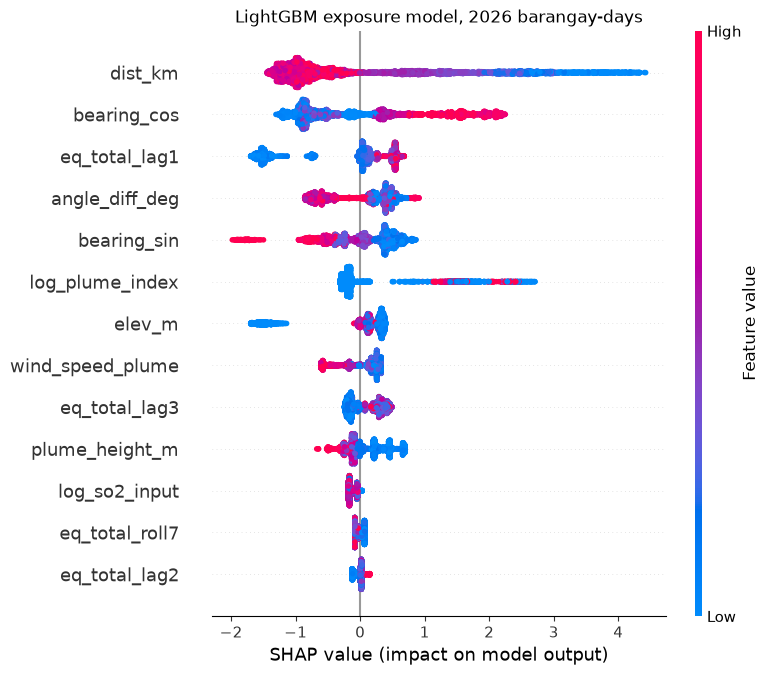

Mean absolute SHAP value, 2026


dist_km             1.218
bearing_cos         0.886
eq_total_lag1       0.596
angle_diff_deg      0.461
bearing_sin         0.439
elev_m              0.413
log_plume_index     0.412
wind_speed_plume    0.253
eq_total_lag3       0.230
plume_height_m      0.228
log_so2_input       0.129
eq_total_roll7      0.060
eq_total_lag2       0.040
dtype: float64

In [25]:
test_rows = panel[panel["split"] == "test"].reset_index(drop=True)
explainer = shap.TreeExplainer(exp_lgbm_search.best_estimator_)
shap_test = explainer.shap_values(test_rows[EXPOSURE_FEATURES])
if isinstance(shap_test, list):
    shap_test = shap_test[1]
print(f"SHAP values: {shap_test.shape[0]:,} rows x {shap_test.shape[1]} features")

sample = np.random.default_rng(RANDOM_STATE).choice(len(test_rows), size=5000, replace=False)
shap.summary_plot(shap_test[sample], test_rows.loc[sample, EXPOSURE_FEATURES], show=False)
plt.title("LightGBM exposure model, 2026 barangay-days")
plt.savefig(FIGURES / "exposure_shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

print("Mean absolute SHAP value, 2026")
pd.Series(np.abs(shap_test).mean(axis=0), index=EXPOSURE_FEATURES).sort_values(ascending=False).round(3)

In [26]:
feature_names = np.array(EXPOSURE_FEATURES)
top_idx = np.argsort(-np.abs(shap_test), axis=1)[:, :3]
rows = np.arange(len(test_rows))
shap_top3 = pd.DataFrame({"psgc_code": test_rows["adm4_psgc"], "date": test_rows["date"].dt.date})
for k in range(3):
    shap_top3[f"top{k + 1}_feature"] = feature_names[top_idx[:, k]]
    shap_top3[f"top{k + 1}_shap"] = shap_test[rows, top_idx[:, k]].round(4)
show(shap_top3, "exposure_shap_top3")
shap_top3.to_csv(PROCESSED / "exposure_shap_top3.csv", index=False)
print("most important feature per barangay-day, 2026:")
print(shap_top3["top1_feature"].value_counts().to_string())

exposure_shap_top3: 63,504 rows x 8 columns
  missing: none
most important feature per barangay-day, 2026:
top1_feature
dist_km             23313
bearing_cos         15916
eq_total_lag1       10270
elev_m               6822
log_plume_index      5167
bearing_sin          1426
angle_diff_deg        558
wind_speed_plume       23
plume_height_m          9


## Scores and forecasts for every date

The final exposure model scores all 221,400 barangay-days with the 2024-2025 threshold; on days without a report
this is an extrapolation, since it was trained on report days only. On 2026-10-21 there is no wind data, so the
plume index is empty and the score relies on the other features.

In [27]:
panel["p_exposed"] = exposure_model.predict_proba(panel[EXPOSURE_FEATURES])[:, 1]
panel["flagged"] = (panel["p_exposed"] >= thresholds[EXPOSURE_MODEL]).astype(int)
exposure_scores = (panel[["adm4_psgc", "date", "plume_index", "p_exposed", "flagged", "split"]]
                   .rename(columns={"adm4_psgc": "psgc_code"}))
exposure_scores["date"] = exposure_scores["date"].dt.date
show(exposure_scores, "exposure_scores")
assert len(exposure_scores) == 221_400
exposure_scores.to_csv(PROCESSED / "exposure_scores.csv", index=False)
print(exposure_scores.groupby("split")["flagged"].agg(["sum", "mean"]).round(3).to_string())

exposure_scores: 221,400 rows x 6 columns
  missing: {'plume_index': 216}


         sum   mean
split              
test   14629  0.230
train  32915  0.208


On 2026 days with no reports, the number of flagged barangays per day shows how often the dashboard would raise
alerts on quiet days.

In [28]:
quiet_test = (exposure_scores["split"] == "test") & (panel["report_day"] == 0)
flags_per_day = exposure_scores[quiet_test].groupby("date")["flagged"].sum()
print(f"2026 days with no reports: {len(flags_per_day)}")
print(f"barangays flagged per day (of 216): mean {flags_per_day.mean():.1f}, "
      f"median {flags_per_day.median():.0f}, max {flags_per_day.max()}")
print(f"days with at least one flagged barangay: {(flags_per_day > 0).sum()} of {len(flags_per_day)}")

2026 days with no reports: 289
barangays flagged per day (of 216): mean 49.8, median 54, max 93
days with at least one flagged barangay: 289 of 289


Each row of the forecast table is the forecast for `date`, made with data up to the day before. The drift
forecast is left empty when there is no wind for that date.

In [29]:
next_day_forecasts = pd.DataFrame({
    "date": daily["target_date"].dt.date,
    "so2_forecast_td": daily["so2_forecast_next_td"].round(1),
    "drift_forecast_sector": daily["drift_forecast_next_sector"].where(daily["next_wind_speed"].notna()),
    "drift_forecast_prob": daily["drift_forecast_next_prob"].where(daily["next_wind_speed"].notna()).round(3),
}).reset_index(drop=True)
next_day_forecasts["split"] = np.where(daily["target_date"].to_numpy() <= TRAIN_END, "train", "test")
show(next_day_forecasts, "next_day_forecasts")
next_day_forecasts.to_csv(PROCESSED / "next_day_forecasts.csv", index=False)
print("dates:", next_day_forecasts["date"].min(), "to", next_day_forecasts["date"].max())

next_day_forecasts: 1,025 rows x 5 columns
  missing: {'drift_forecast_sector': 2, 'drift_forecast_prob': 2}
dates: 2024-01-02 to 2026-10-22


## Results

Metrics go to `results/metrics.json` (other notebooks' keys are kept), and the final and comparison models with
every baseline to `results/tables/model_comparison.csv`.

In [30]:
metrics_path = RESULTS / "metrics.json"
all_metrics = json.loads(metrics_path.read_text()) if metrics_path.exists() else {}
all_metrics.update(metrics)
metrics_path.write_text(json.dumps(all_metrics, indent=2, default=float))

COMPARISON_COLUMNS = ["task", "model", "kind", "mae_td", "rmse_td", "accuracy", "within_one_accuracy",
                      "recall", "precision", "f1", "pr_auc", "n_flagged", "n_positive", "n_eval"]
model_comparison = pd.DataFrame(comparison).reindex(columns=COMPARISON_COLUMNS)
model_comparison.to_csv(TABLES / "model_comparison.csv", index=False, float_format="%.4f")
print(f"model_comparison: {len(model_comparison)} rows")
model_comparison.round(3)

model_comparison: 14 rows


,task,model,kind,mae_td,rmse_td,accuracy,within_one_accuracy,recall,precision,f1,pr_auc,n_flagged,n_positive,n_eval
0,next-day SO2,LightGBM,model,687.908,875.248,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,290.0
1,next-day SO2,MLP,model,633.423,807.837,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,290.0
2,next-day SO2,persistence,baseline,784.270,1021.336,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,290.0
3,next-day SO2,7-day mean,baseline,657.812,821.252,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,290.0
4,next-day drift,LightGBM,model,NaN,NaN,0.558,0.887,NaN,NaN,NaN,NaN,NaN,NaN,265.0
5,next-day drift,MLP,model,NaN,NaN,0.509,0.875,NaN,NaN,NaN,NaN,NaN,NaN,265.0
6,next-day drift,repeat yesterday,baseline,NaN,NaN,0.430,0.770,NaN,NaN,NaN,NaN,NaN,NaN,265.0
7,next-day drift,always SW,baseline,NaN,NaN,0.355,0.596,NaN,NaN,NaN,NaN,NaN,NaN,265.0
8,next-day drift,wind sector (reference),reference,NaN,NaN,0.483,0.932,NaN,NaN,NaN,NaN,NaN,NaN,265.0
9,exposure,LightGBM,model,NaN,NaN,NaN,NaN,0.641,0.246,0.355,0.452,240.0,92.0,1080.0


Each task has a final model, the one with the best 2024-2025 cross-validation score (next-day SO2: MLP, drift: MLP,
exposure: LightGBM) and marked by `used_downstream`, and a comparison model, the other one. Both are shown against
their baselines and targets on 2026. Next-day SO2 has no numeric target, so its criterion is a lower
MAE than both baselines.

In [31]:
MODEL_NAMES = ["LightGBM", "MLP"]
so2_baseline = so2_results.loc[["persistence", "7-day mean"], "mae_td"]
drift_baseline = drift_results.loc[["repeat yesterday", "always SW"], "accuracy"]
target_summary = pd.DataFrame(
    [{"task": "next-day SO2", "model": m, "used_downstream": m == SO2_FORECAST_MODEL, "measure": "MAE (t/d)",
      "value": so2_results.loc[m, "mae_td"], "best_baseline": so2_baseline.idxmin(),
      "baseline_value": so2_baseline.min(), "criterion": "MAE below both baselines",
      "met": so2_results.loc[m, "mae_td"] < so2_baseline.min()} for m in MODEL_NAMES]
    + [{"task": "next-day drift", "model": m, "used_downstream": m == DRIFT_FORECAST_MODEL, "measure": "accuracy",
        "value": drift_results.loc[m, "accuracy"], "best_baseline": drift_baseline.idxmax(),
        "baseline_value": drift_baseline.max(), "criterion": f"accuracy >= {TARGET_DRIFT_ACCURACY:.0%}",
        "met": drift_results.loc[m, "accuracy"] >= TARGET_DRIFT_ACCURACY} for m in MODEL_NAMES]
    + [{"task": "exposure", "model": m, "used_downstream": m == EXPOSURE_MODEL, "measure": "recall",
        "value": exp_results.loc[m, "recall"], "best_baseline": f"distance only (N from {m})",
        "baseline_value": exp_results.loc[f"distance only (N from {m})", "recall"],
        "criterion": f"recall >= {TARGET_RECALL:.0%} and above distance only",
        "met": (exp_results.loc[m, "recall"] >= TARGET_RECALL)
               and (exp_results.loc[m, "recall"] > exp_results.loc[f"distance only (N from {m})", "recall"])}
       for m in MODEL_NAMES])
target_summary.round(3)

,task,model,used_downstream,measure,value,best_baseline,baseline_value,criterion,met
0,next-day SO2,LightGBM,False,MAE (t/d),687.908,7-day mean,657.812,MAE below both baselines,False
1,next-day SO2,MLP,True,MAE (t/d),633.423,7-day mean,657.812,MAE below both baselines,True
2,next-day drift,LightGBM,False,accuracy,0.558,repeat yesterday,0.430,accuracy >= 60%,False
3,next-day drift,MLP,True,accuracy,0.509,repeat yesterday,0.430,accuracy >= 60%,False
4,exposure,LightGBM,True,recall,0.641,distance only (N from LightGBM),0.543,recall >= 75% and above distance only,False
5,exposure,MLP,False,recall,0.652,distance only (N from MLP),0.522,recall >= 75% and above distance only,False
